<a href="https://colab.research.google.com/github/Shaurya-XD/MotionMirror/blob/main/MotionMirror_Model_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import os
import pandas as pd
import torch

# Main MotionMirror project folder.
PROJECT_DIR = "/content/drive/MyDrive/MotionMirror"

# Existing HMDB51 dataset folder.
HMDB_DRIVE_DIR = os.path.join(
    PROJECT_DIR,
    "datasets",
    "HMDB51"
)

# Existing five-class manifest.
MANIFEST_PATH = os.path.join(
    HMDB_DRIVE_DIR,
    "metadata",
    "p2_split1_manifest.csv"
)

# Existing original video archive.
DRIVE_VIDEO_ARCHIVE = os.path.join(
    HMDB_DRIVE_DIR,
    "hmdb51_org.rar"
)

# Preserve the same working directory paths
# used in our five-class training notebook.
WORK_DIR = "/content/HMDB51_P2"

CLASS_ARCHIVE_DIR = os.path.join(
    WORK_DIR,
    "class_archives"
)

VIDEO_DIR = os.path.join(
    WORK_DIR,
    "videos"
)

# All four models will have checkpoints here.
CHECKPOINT_DIR = os.path.join(
    PROJECT_DIR,
    "checkpoints"
)

# Final action classes.
SELECTED_CLASSES = [
    "walk",
    "pushup",
    "sit",
    "drink",
    "clap"
]

NUM_CLASSES = len(SELECTED_CLASSES)
SEED = 7

CLASS_TO_INDEX = {
    action: index
    for index, action in enumerate(SELECTED_CLASSES)
}

INDEX_TO_CLASS = {
    index: action
    for action, index in CLASS_TO_INDEX.items()
}

# Confirm that the required saved files exist.
BASELINE_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "r2plus1d_best.pth"
)

for FILE_PATH in [
    MANIFEST_PATH,
    DRIVE_VIDEO_ARCHIVE,
    BASELINE_CHECKPOINT_PATH
]:
    if not os.path.isfile(FILE_PATH):
        raise FileNotFoundError(FILE_PATH)

print("Existing project files verified.")
print("Selected classes:", SELECTED_CLASSES)
print("Number of classes:", NUM_CLASSES)

Existing project files verified.
Selected classes: ['walk', 'pushup', 'sit', 'drink', 'clap']
Number of classes: 5


In [ ]:
# Load the exact five-class split from our baseline.
manifest_df = pd.read_csv(MANIFEST_PATH)

# Separate the three partitions.
train_df = manifest_df[
    manifest_df["split"] == "train"
].reset_index(drop=True)

val_df = manifest_df[
    manifest_df["split"] == "validation"
].reset_index(drop=True)

test_df = manifest_df[
    manifest_df["split"] == "test"
].reset_index(drop=True)

# Verify that the manifest is correct.
assert len(train_df) == 280
assert len(val_df) == 70
assert len(test_df) == 150

assert set(manifest_df["action"]) == set(SELECTED_CLASSES)

# Verify that class labels match our defined ordering.
for action, label in CLASS_TO_INDEX.items():

    class_labels = manifest_df.loc[
        manifest_df["action"] == action,
        "label"
    ]

    assert (class_labels == label).all()

# Verify that no video appears more than once.
assert manifest_df["video_path"].is_unique

print("Training videos:", len(train_df))
print("Validation videos:", len(val_df))
print("Testing videos:", len(test_df))

print("\nVideos per class:")
print(
    manifest_df.groupby(
        ["action", "split"]
    ).size().unstack(fill_value=0)
)

Training videos: 280
Validation videos: 70
Testing videos: 150

Videos per class:
split   test  train  validation
action                         
clap      30     56          14
drink     30     56          14
pushup    30     56          14
sit       30     56          14
walk      30     56          14


In [ ]:
# Install unrar to extract the HMDB51 class archives.

!apt-get update -qq
!apt-get install -y -qq unrar

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
# Create local folders if they do not exist.
os.makedirs(CLASS_ARCHIVE_DIR, exist_ok=True)
os.makedirs(VIDEO_DIR, exist_ok=True)

# Check whether the five class archives are available.
missing_archives = [
    action
    for action in SELECTED_CLASSES
    if not os.path.isfile(
        os.path.join(CLASS_ARCHIVE_DIR, f"{action}.rar")
    )
]

# Extract the outer archive only when needed.
if missing_archives:

    print("Restoring class archives from Google Drive.")

    !unrar x -o+ "$DRIVE_VIDEO_ARCHIVE" "$CLASS_ARCHIVE_DIR/" > /dev/null

# Extract actual video files only for missing classes.
for action in SELECTED_CLASSES:

    ACTION_DIR = os.path.join(
        VIDEO_DIR,
        action,
        action
    )

    ARCHIVE_PATH = os.path.join(
        CLASS_ARCHIVE_DIR,
        f"{action}.rar"
    )

    # Check whether this class was already extracted.
    videos_exist = (
        os.path.isdir(ACTION_DIR)
        and any(
            file_name.lower().endswith(".avi")
            for file_name in os.listdir(ACTION_DIR)
        )
    )

    if videos_exist:
        print(f"{action}: Already extracted")
        continue

    print(f"Extracting {action}...")

    ACTION_OUTPUT_DIR = os.path.join(
        VIDEO_DIR,
        action
    )

    os.makedirs(ACTION_OUTPUT_DIR, exist_ok=True)

    !unrar x -o+ "$ARCHIVE_PATH" "$ACTION_OUTPUT_DIR/" > /dev/null

print("Video extraction check completed.")

Restoring class archives from Google Drive.
Extracting walk...
Extracting pushup...
Extracting sit...
Extracting drink...
Extracting clap...
Video extraction check completed.


In [ ]:
# Every video referenced by the manifest must exist.

missing_videos = [
    video_path
    for video_path in manifest_df["video_path"]
    if not os.path.isfile(video_path)
]

if missing_videos:
    raise FileNotFoundError(
        f"{len(missing_videos)} manifest videos are missing."
    )

print("All 500 manifest videos are available.")

All 500 manifest videos are available.


In [ ]:
import cv2
import random
import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import RandomResizedCrop
from torchvision.transforms import functional as TF
from torchvision.transforms.functional import InterpolationMode

from torchvision.models.video import (
    r3d_18,
    mc3_18,
    mvit_v2_s,
    R3D_18_Weights,
    MC3_18_Weights,
    MViT_V2_S_Weights
)

# Each model has its own pretrained weights and input settings.
MODEL_CONFIGS = {
    "r3d_18": {
        "weights": R3D_18_Weights.KINETICS400_V1,
        "num_frames": 16,
        "temporal_window_seconds": 2.0,
        "batch_size": 4
    },
    "mc3_18": {
        "weights": MC3_18_Weights.KINETICS400_V1,
        "num_frames": 16,
        "temporal_window_seconds": 2.0,
        "batch_size": 4
    },
    "mvit_v2_s": {
        "weights": MViT_V2_S_Weights.KINETICS400_V1,
        "num_frames": 16,
        "temporal_window_seconds": 2.0,
        "batch_size": 2
    }
}

# Train R3D-18 first.
MODEL_NAME = "r3d_18"

MODEL_CONFIG = MODEL_CONFIGS[MODEL_NAME]

# Retrieve the preprocessing specification associated
# with the selected pretrained weights.
PREPROCESS = MODEL_CONFIG["weights"].transforms()

NUM_FRAMES = MODEL_CONFIG["num_frames"]
FRAME_SIZE = PREPROCESS.crop_size[0]
BATCH_SIZE = MODEL_CONFIG["batch_size"]

print("Selected model:", MODEL_NAME)
print("Frames:", NUM_FRAMES)
print("Frame size:", FRAME_SIZE)
print("Resize dimensions:", PREPROCESS.resize_size)
print("Normalization mean:", PREPROCESS.mean)
print("Normalization std:", PREPROCESS.std)
print("Batch size:", BATCH_SIZE)

Selected model: r3d_18
Frames: 16
Frame size: 112
Resize dimensions: [128, 171]
Normalization mean: [0.43216, 0.394666, 0.37645]
Normalization std: [0.22803, 0.22145, 0.216989]
Batch size: 4


In [ ]:
# Decode a video into RGB frames and return its FPS.

def decode_video(video_path):

    video_capture = cv2.VideoCapture(video_path)

    if not video_capture.isOpened():
        raise RuntimeError(
            f"Could not open video: {video_path}"
        )

    fps = video_capture.get(cv2.CAP_PROP_FPS)
    frames = []

    while True:

        success, frame = video_capture.read()

        if not success:
            break

        # OpenCV produces BGR frames; convert to RGB.
        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        frames.append(frame)

    video_capture.release()

    if not frames:
        raise RuntimeError(
            f"No frames decoded: {video_path}"
        )

    # Convert [T, H, W, C] into [T, C, H, W].
    frames = (
        torch.from_numpy(np.stack(frames))
        .permute(0, 3, 1, 2)
        .float() / 255.0
    )

    return frames, fps


# Select frames from a fixed-duration temporal window.
def sample_temporal_frames(
    frames,
    fps,
    training,
    num_frames,
    window_seconds
):

    total_frames = frames.shape[0]

    # Use FPS when available to find the window length.
    if np.isfinite(fps) and fps > 0:
        temporal_window = round(window_seconds * fps)
    else:
        temporal_window = num_frames * 2

    temporal_window = max(
        1,
        min(temporal_window, total_frames)
    )

    max_start = total_frames - temporal_window

    if training:
        # Random temporal crop during training.
        start_frame = random.randint(0, max_start)
    else:
        # Deterministic center crop during validation.
        start_frame = max_start // 2

    end_frame = start_frame + temporal_window - 1

    frame_indices = (
        torch.linspace(
            start_frame,
            end_frame,
            steps=num_frames
        )
        .round()
        .long()
        .clamp(0, total_frames - 1)
    )

    return frames[frame_indices]

In [ ]:
# Apply consistent spatial augmentation to all
# frames of the same training clip.

def apply_training_augmentation(frames, frame_size):

    top, left, height, width = RandomResizedCrop.get_params(
        frames[0],
        scale=(0.80, 1.00),
        ratio=(0.90, 1.10)
    )

    frames = TF.resized_crop(
        frames,
        top,
        left,
        height,
        width,
        size=[frame_size, frame_size],
        interpolation=InterpolationMode.BILINEAR,
        antialias=True
    )

    # Random horizontal flipping.
    if random.random() < 0.50:
        frames = TF.hflip(frames)

    # Small rotation, translation, and scale changes.
    angle = random.uniform(-7.0, 7.0)

    max_translation = round(frame_size * 0.05)

    translate_x = random.randint(
        -max_translation,
        max_translation
    )

    translate_y = random.randint(
        -max_translation,
        max_translation
    )

    spatial_scale = random.uniform(0.95, 1.05)

    frames = TF.affine(
        frames,
        angle=angle,
        translate=[translate_x, translate_y],
        scale=spatial_scale,
        shear=[0.0, 0.0],
        interpolation=InterpolationMode.BILINEAR
    )

    # Apply color adjustments consistently to the clip.
    frames = TF.adjust_brightness(
        frames,
        random.uniform(0.85, 1.15)
    )

    frames = TF.adjust_contrast(
        frames,
        random.uniform(0.85, 1.15)
    )

    frames = TF.adjust_saturation(
        frames,
        random.uniform(0.90, 1.10)
    )

    # Occasional small blur.
    if random.random() < 0.10:
        frames = TF.gaussian_blur(
            frames,
            kernel_size=[3, 3]
        )

    return frames.clamp(0.0, 1.0)


# Complete preprocessing for one video.
def prepare_video_clip(
    video_path,
    training,
    model_config,
    preprocess
):

    # Decode the original video.
    frames, fps = decode_video(video_path)

    # Extract the required number of temporal frames.
    frames = sample_temporal_frames(
        frames=frames,
        fps=fps,
        training=training,
        num_frames=model_config["num_frames"],
        window_seconds=model_config["temporal_window_seconds"]
    )

    if training:

        frames = apply_training_augmentation(
            frames,
            frame_size=preprocess.crop_size[0]
        )

    else:

        # Model-specific deterministic evaluation preprocessing.
        frames = TF.resize(
            frames,
            size=preprocess.resize_size,
            interpolation=InterpolationMode.BILINEAR,
            antialias=True
        )

        frames = TF.center_crop(
            frames,
            output_size=preprocess.crop_size
        )

    # Normalize using the selected pretrained model's statistics.
    mean = torch.tensor(
        preprocess.mean,
        dtype=frames.dtype
    ).view(1, 3, 1, 1)

    std = torch.tensor(
        preprocess.std,
        dtype=frames.dtype
    ).view(1, 3, 1, 1)

    frames = (frames - mean) / std

    # Convert [T, C, H, W] into [C, T, H, W].
    frames = frames.permute(
        1, 0, 2, 3
    ).contiguous()

    return frames

In [ ]:
class HMDBVideoDataset(Dataset):

    def __init__(self, dataframe, model_config, training):

        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.model_config = model_config
        self.training = training

        # Store the pretrained preprocessing specification.
        self.preprocess = (
            model_config["weights"].transforms()
        )

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        video_path = row["video_path"]
        label = int(row["label"])

        video_clip = prepare_video_clip(
            video_path=video_path,
            training=self.training,
            model_config=self.model_config,
            preprocess=self.preprocess
        )

        return video_clip, label


# Preserve the previous project's reproducibility settings.
def seed_worker(worker_id):

    worker_seed = torch.initial_seed() % (2 ** 32)

    np.random.seed(worker_seed)
    random.seed(worker_seed)


data_loader_generator = torch.Generator()
data_loader_generator.manual_seed(SEED)

NUM_WORKERS = 2
PIN_MEMORY = torch.cuda.is_available()

# Avoid CPU thread competition during video decoding.
cv2.setNumThreads(0)

# Training data uses random augmentation.
train_dataset = HMDBVideoDataset(
    dataframe=train_df,
    model_config=MODEL_CONFIG,
    training=True
)

# Validation data uses deterministic preprocessing.
val_dataset = HMDBVideoDataset(
    dataframe=val_df,
    model_config=MODEL_CONFIG,
    training=False
)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    worker_init_fn=seed_worker,
    generator=data_loader_generator,
    persistent_workers=(NUM_WORKERS > 0)
)

val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    worker_init_fn=seed_worker,
    persistent_workers=(NUM_WORKERS > 0)
)

print("Training videos:", len(train_dataset))
print("Validation videos:", len(val_dataset))

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training videos: 280
Validation videos: 70
Training batches: 70
Validation batches: 18


In [ ]:
# Retrieve one video from the training dataset.

sample_video, sample_label = train_dataset[0]

print("Video shape:", sample_video.shape)
print("Numeric label:", sample_label)
print("Action:", INDEX_TO_CLASS[sample_label])

assert sample_video.shape == (
    3,
    NUM_FRAMES,
    FRAME_SIZE,
    FRAME_SIZE
)

# Retrieve one batch.
batch_videos, batch_labels = next(iter(train_loader))

print("Batch shape:", batch_videos.shape)
print("Labels shape:", batch_labels.shape)

assert batch_videos.shape == (
    BATCH_SIZE,
    3,
    NUM_FRAMES,
    FRAME_SIZE,
    FRAME_SIZE
)

assert batch_labels.min().item() >= 0
assert batch_labels.max().item() < NUM_CLASSES

print("Preprocessing and DataLoader verification passed.")

Video shape: torch.Size([3, 16, 112, 112])
Numeric label: 1
Action: pushup
Batch shape: torch.Size([4, 3, 16, 112, 112])
Labels shape: torch.Size([4])
Preprocessing and DataLoader verification passed.


In [ ]:
# Select GPU when available.
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

# Load Kinetics-400 pretrained R3D-18.
model = r3d_18(
    weights=MODEL_CONFIG["weights"]
)

# Freeze the entire pretrained backbone.
for parameter in model.parameters():
    parameter.requires_grad = False

# Replace the original 400-class classifier.
CLASSIFIER_INPUT_FEATURES = model.fc.in_features

model.fc = nn.Sequential(
    nn.Dropout(p=0.50),
    nn.Linear(
        CLASSIFIER_INPUT_FEATURES,
        NUM_CLASSES
    )
)

# The new classifier parameters are trainable by default.
model = model.to(DEVICE)

print("New classifier:")
print(model.fc)

# Verify the model output using one training batch.
model.eval()

with torch.inference_mode():

    logits = model(
        batch_videos.to(DEVICE)
    )

print("Input shape:", batch_videos.shape)
print("Output shape:", logits.shape)

assert logits.shape == (
    BATCH_SIZE,
    NUM_CLASSES
)

print("R3D-18 model verification passed.")

Device: cuda
Downloading: "https://download.pytorch.org/models/r3d_18-b3b3357e.pth" to /root/.cache/torch/hub/checkpoints/r3d_18-b3b3357e.pth


100%|██████████| 127M/127M [00:01<00:00, 82.7MB/s]


New classifier:
Sequential(
  (0): Dropout(p=0.5, inplace=False)
  (1): Linear(in_features=512, out_features=5, bias=True)
)
Input shape: torch.Size([4, 3, 16, 112, 112])
Output shape: torch.Size([4, 5])
R3D-18 model verification passed.


In [ ]:
from torch.optim import AdamW
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

# Stage 1 training settings.
STAGE1_EPOCHS = 8
STAGE1_LEARNING_RATE = 1e-3
STAGE1_WEIGHT_DECAY = 1e-4

EARLY_STOPPING_PATIENCE = 3

# Use mixed precision when running on a CUDA GPU.
USE_AMP = DEVICE.type == "cuda"

# Create separate checkpoint and result paths for this model.
MODEL_CHECKPOINT_DIR = os.path.join(
    CHECKPOINT_DIR,
    MODEL_NAME
)

MODEL_RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "model_comparison",
    MODEL_NAME
)

os.makedirs(MODEL_CHECKPOINT_DIR, exist_ok=True)
os.makedirs(MODEL_RESULTS_DIR, exist_ok=True)

STAGE1_CHECKPOINT_PATH = os.path.join(
    MODEL_CHECKPOINT_DIR,
    "stage1_best.pth"
)

STAGE1_HISTORY_PATH = os.path.join(
    MODEL_RESULTS_DIR,
    "stage1_history.csv"
)

# Classification loss.
criterion = nn.CrossEntropyLoss()

# Stage 1 only updates the new classification head.
optimizer = AdamW(
    [
        parameter
        for parameter in model.parameters()
        if parameter.requires_grad
    ],
    lr=STAGE1_LEARNING_RATE,
    weight_decay=STAGE1_WEIGHT_DECAY
)

# Gradient scaling prevents float16 gradient underflow.
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

print("Model:", MODEL_NAME)
print("Stage 1 epochs:", STAGE1_EPOCHS)
print("Learning rate:", STAGE1_LEARNING_RATE)
print("Mixed precision:", USE_AMP)
print("Checkpoint:", STAGE1_CHECKPOINT_PATH)

print(
    "Trainable parameters:",
    sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )
)

Model: r3d_18
Stage 1 epochs: 8
Learning rate: 0.001
Mixed precision: True
Checkpoint: /content/drive/MyDrive/MotionMirror/checkpoints/r3d_18/stage1_best.pth
Trainable parameters: 2565


In [ ]:
def train_one_epoch(
    model,
    data_loader,
    criterion,
    optimizer,
    scaler,
    device,
    trainable_modules
):

    # Keep frozen parts of the model in evaluation mode.
    model.eval()

    # Enable training behavior only for selected modules.
    for module_name in trainable_modules:
        model.get_submodule(module_name).train()

    running_loss = 0.0
    total_samples = 0
    correct_predictions = 0

    all_predictions = []
    all_labels = []

    progress_bar = tqdm(
        data_loader,
        desc="Training",
        leave=False
    )

    for videos, labels in progress_bar:

        videos = videos.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        # Reset gradients from the previous batch.
        optimizer.zero_grad(
            set_to_none=True
        )

        # Use automatic mixed precision when available.
        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=USE_AMP
        ):

            logits = model(videos)

            loss = criterion(
                logits,
                labels
            )

        # Calculate gradients and update trainable weights.
        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        # Convert output logits into predicted class indices.
        predictions = torch.argmax(
            logits,
            dim=1
        )

        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size

        correct_predictions += (
            predictions == labels
        ).sum().item()

        total_samples += batch_size

        all_predictions.extend(
            predictions.detach().cpu().tolist()
        )

        all_labels.extend(
            labels.detach().cpu().tolist()
        )

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    # Calculate average metrics over the complete epoch.
    average_loss = running_loss / total_samples

    accuracy = correct_predictions / total_samples

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    return average_loss, accuracy, macro_f1

In [ ]:
def validate_one_epoch(
    model,
    data_loader,
    criterion,
    device
):

    # Disable training behavior for all model modules.
    model.eval()

    running_loss = 0.0
    total_samples = 0
    correct_predictions = 0

    all_predictions = []
    all_labels = []

    # No gradients are required during validation.
    with torch.inference_mode():

        for videos, labels in tqdm(
            data_loader,
            desc="Validation",
            leave=False
        ):

            videos = videos.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=USE_AMP
            ):

                logits = model(videos)

                loss = criterion(
                    logits,
                    labels
                )

            predictions = torch.argmax(
                logits,
                dim=1
            )

            batch_size = labels.size(0)

            running_loss += loss.item() * batch_size

            correct_predictions += (
                predictions == labels
            ).sum().item()

            total_samples += batch_size

            all_predictions.extend(
                predictions.cpu().tolist()
            )

            all_labels.extend(
                labels.cpu().tolist()
            )

    average_loss = running_loss / total_samples

    accuracy = correct_predictions / total_samples

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    return average_loss, accuracy, macro_f1

In [ ]:
def fit_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scaler,
    device,
    model_name,
    model_config,
    trainable_modules,
    num_epochs,
    patience,
    checkpoint_path,
    history_path,
    stage
):

    # Store the metrics of all completed epochs.
    history = {
        "train_loss": [],
        "train_accuracy": [],
        "train_f1": [],
        "val_loss": [],
        "val_accuracy": [],
        "val_f1": []
    }

    best_val_f1 = -1.0
    epochs_without_improvement = 0

    for epoch in range(num_epochs):

        print(
            f"\n{model_name} - {stage} - "
            f"Epoch {epoch + 1}/{num_epochs}"
        )

        train_loss, train_accuracy, train_f1 = train_one_epoch(
            model=model,
            data_loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            scaler=scaler,
            device=device,
            trainable_modules=trainable_modules
        )

        val_loss, val_accuracy, val_f1 = validate_one_epoch(
            model=model,
            data_loader=val_loader,
            criterion=criterion,
            device=device
        )

        # Record training and validation metrics.
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["train_f1"].append(train_f1)

        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        history["val_f1"].append(val_f1)

        print(
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Train F1: {train_f1:.4f}"
        )

        print(
            f"Val Loss:   {val_loss:.4f} | "
            f"Val Acc:   {val_accuracy:.4f} | "
            f"Val F1: {val_f1:.4f}"
        )

        # Save training history after every epoch.
        pd.DataFrame(history).to_csv(
            history_path,
            index=False
        )

        # Save the checkpoint only when validation improves.
        if val_f1 > best_val_f1:

            best_val_f1 = val_f1
            epochs_without_improvement = 0

            preprocess = model_config["weights"].transforms()

            checkpoint = {
                "model_name": model_name,
                "stage": stage,
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "val_f1": float(val_f1),
                "val_accuracy": float(val_accuracy),
                "class_to_index": CLASS_TO_INDEX,
                "num_frames": model_config["num_frames"],
                "frame_size": preprocess.crop_size[0],
                "temporal_window_seconds": model_config[
                    "temporal_window_seconds"
                ],
                "normalization_mean": list(preprocess.mean),
                "normalization_std": list(preprocess.std)
            }

            torch.save(
                checkpoint,
                checkpoint_path
            )

            print(
                f"Best checkpoint saved "
                f"(Val F1: {val_f1:.4f})"
            )

        else:

            epochs_without_improvement += 1

            print(
                "No improvement for",
                epochs_without_improvement,
                "epoch(s)."
            )

        # Stop if validation has not improved.
        if epochs_without_improvement >= patience:
            print("Early stopping triggered.")
            break

    print(
        f"\nBest {stage} validation F1:",
        f"{best_val_f1:.4f}"
    )

    return history

In [ ]:
# Train only the new R3D classifier.
STAGE1_TRAINABLE_MODULES = ("fc",)

stage1_history = fit_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=DEVICE,
    model_name=MODEL_NAME,
    model_config=MODEL_CONFIG,
    trainable_modules=STAGE1_TRAINABLE_MODULES,
    num_epochs=STAGE1_EPOCHS,
    patience=EARLY_STOPPING_PATIENCE,
    checkpoint_path=STAGE1_CHECKPOINT_PATH,
    history_path=STAGE1_HISTORY_PATH,
    stage="stage1"
)


r3d_18 - stage1 - Epoch 1/8


Training:   0%|          | 0/70 [00:00<?, ?it/s]

Validation:   0%|          | 0/18 [00:00<?, ?it/s]

Train Loss: 1.5061 | Train Acc: 0.3464 | Train F1: 0.3465
Val Loss:   1.1384 | Val Acc:   0.5286 | Val F1: 0.4919
Best checkpoint saved (Val F1: 0.4919)

r3d_18 - stage1 - Epoch 2/8


Training:   0%|          | 0/70 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/18 [00:00<?, ?it/s]

Train Loss: 0.4723 | Train Acc: 0.8286 | Train F1: 0.8274
Val Loss:   0.5560 | Val Acc:   0.7571 | Val F1: 0.7554
No improvement for 1 epoch(s).

r3d_18 - stage1 - Epoch 8/8


Training:   0%|          | 0/70 [00:00<?, ?it/s]

Validation:   0%|          | 0/18 [00:00<?, ?it/s]

Train Loss: 0.4552 | Train Acc: 0.8429 | Train F1: 0.8417
Val Loss:   0.5585 | Val Acc:   0.7714 | Val F1: 0.7716
No improvement for 2 epoch(s).

Best stage1 validation F1: 0.7884


Model: r3d_18
Best epoch: 6
Best validation F1: 0.7884
Best validation accuracy: 0.7857


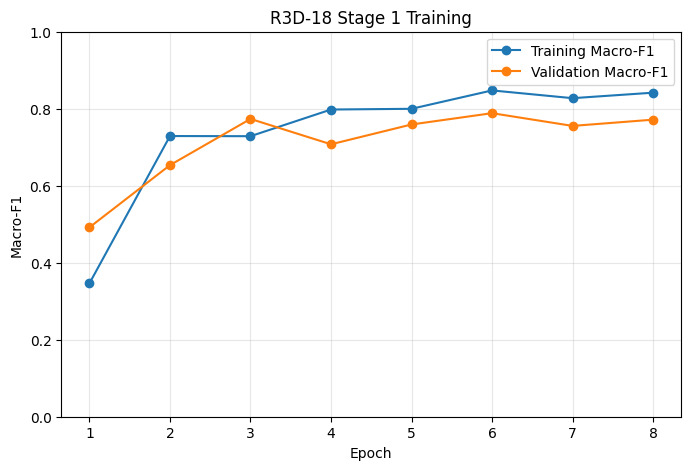

Training history: /content/drive/MyDrive/MotionMirror/results/model_comparison/r3d_18/stage1_history.csv
Learning curve: /content/drive/MyDrive/MotionMirror/results/model_comparison/r3d_18/stage1_f1_curve.png


In [ ]:
import matplotlib.pyplot as plt

# Load the best Stage 1 checkpoint.
stage1_checkpoint = torch.load(
    STAGE1_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(
    stage1_checkpoint["model_state_dict"]
)

model.eval()

print("Model:", stage1_checkpoint["model_name"])
print("Best epoch:", stage1_checkpoint["epoch"])

print(
    "Best validation F1:",
    f"{stage1_checkpoint['val_f1']:.4f}"
)

print(
    "Best validation accuracy:",
    f"{stage1_checkpoint['val_accuracy']:.4f}"
)

# Plot the learning curves using the actual completed epochs.
epochs_completed = range(
    1,
    len(stage1_history["train_f1"]) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_completed,
    stage1_history["train_f1"],
    marker="o",
    label="Training Macro-F1"
)

plt.plot(
    epochs_completed,
    stage1_history["val_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("R3D-18 Stage 1 Training")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)

# Save the graph for the mini-project report.
STAGE1_PLOT_PATH = os.path.join(
    MODEL_RESULTS_DIR,
    "stage1_f1_curve.png"
)

plt.savefig(
    STAGE1_PLOT_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Training history:", STAGE1_HISTORY_PATH)
print("Learning curve:", STAGE1_PLOT_PATH)

In [ ]:
# Restore the best Stage 1 weights before fine-tuning.
# This ensures Stage 2 always begins from the selected
# Stage 1 checkpoint.

stage1_checkpoint = torch.load(
    STAGE1_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(
    stage1_checkpoint["model_state_dict"]
)

# First, freeze the entire R3D network.
for parameter in model.parameters():
    parameter.requires_grad = False

# Unfreeze the final pretrained feature extraction block.
for parameter in model.layer4.parameters():
    parameter.requires_grad = True

# Keep the five-class classifier trainable.
for parameter in model.fc.parameters():
    parameter.requires_grad = True

# Verify how many parameters will be updated.
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Model:", MODEL_NAME)
print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)
print("Frozen parameters:", total_parameters - trainable_parameters)

Model: r3d_18
Total parameters: 33168837
Trainable parameters: 24911365
Frozen parameters: 8257472


In [ ]:
# Stage 2 hyperparameters.
STAGE2_EPOCHS = 8

STAGE2_BACKBONE_LEARNING_RATE = 1e-5
STAGE2_CLASSIFIER_LEARNING_RATE = 1e-4

STAGE2_WEIGHT_DECAY = 1e-4
STAGE2_EARLY_STOPPING_PATIENCE = 3

# Save Stage 2 separately from Stage 1.
STAGE2_CHECKPOINT_PATH = os.path.join(
    MODEL_CHECKPOINT_DIR,
    "stage2_best.pth"
)

STAGE2_HISTORY_PATH = os.path.join(
    MODEL_RESULTS_DIR,
    "stage2_history.csv"
)

# Give the pretrained backbone and new classifier
# different learning rates.
stage2_optimizer = AdamW(
    [
        {
            "params": model.layer4.parameters(),
            "lr": STAGE2_BACKBONE_LEARNING_RATE
        },
        {
            "params": model.fc.parameters(),
            "lr": STAGE2_CLASSIFIER_LEARNING_RATE
        }
    ],
    weight_decay=STAGE2_WEIGHT_DECAY
)

# Use a fresh gradient scaler for Stage 2.
stage2_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

print("Model:", MODEL_NAME)
print("Stage 2 epochs:", STAGE2_EPOCHS)

print(
    "Backbone learning rate:",
    STAGE2_BACKBONE_LEARNING_RATE
)

print(
    "Classifier learning rate:",
    STAGE2_CLASSIFIER_LEARNING_RATE
)

print("Checkpoint:", STAGE2_CHECKPOINT_PATH)

Model: r3d_18
Stage 2 epochs: 8
Backbone learning rate: 1e-05
Classifier learning rate: 0.0001
Checkpoint: /content/drive/MyDrive/MotionMirror/checkpoints/r3d_18/stage2_best.pth


In [ ]:
# Train layer4 and the five-class classifier.
STAGE2_TRAINABLE_MODULES = (
    "layer4",
    "fc"
)

stage2_history = fit_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=stage2_optimizer,
    scaler=stage2_scaler,
    device=DEVICE,
    model_name=MODEL_NAME,
    model_config=MODEL_CONFIG,
    trainable_modules=STAGE2_TRAINABLE_MODULES,
    num_epochs=STAGE2_EPOCHS,
    patience=STAGE2_EARLY_STOPPING_PATIENCE,
    checkpoint_path=STAGE2_CHECKPOINT_PATH,
    history_path=STAGE2_HISTORY_PATH,
    stage="stage2"
)


r3d_18 - stage2 - Epoch 1/8


Training:   0%|          | 0/70 [00:00<?, ?it/s]

Validation:   0%|          | 0/18 [00:00<?, ?it/s]

Train Loss: 0.8007 | Train Acc: 0.6893 | Train F1: 0.6833
Val Loss:   0.5397 | Val Acc:   0.8000 | Val F1: 0.8001
Best checkpoint saved (Val F1: 0.8001)

r3d_18 - stage2 - Epoch 2/8


Training:   0%|          | 0/70 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/18 [00:00<?, ?it/s]

Train Loss: 0.4391 | Train Acc: 0.8464 | Train F1: 0.8452
Val Loss:   0.4695 | Val Acc:   0.7714 | Val F1: 0.7716
No improvement for 2 epoch(s).

r3d_18 - stage2 - Epoch 7/8


Training:   0%|          | 0/70 [00:00<?, ?it/s]

Validation:   0%|          | 0/18 [00:00<?, ?it/s]

Train Loss: 0.4424 | Train Acc: 0.8429 | Train F1: 0.8423
Val Loss:   0.4340 | Val Acc:   0.8286 | Val F1: 0.8310
No improvement for 3 epoch(s).
Early stopping triggered.

Best stage2 validation F1: 0.8423


In [ ]:
 import shutil

# Load the best checkpoint from each training stage.
stage1_checkpoint = torch.load(
    STAGE1_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

stage2_checkpoint = torch.load(
    STAGE2_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

# Compare the best validation macro-F1 scores.
stage1_f1 = stage1_checkpoint["val_f1"]
stage2_f1 = stage2_checkpoint["val_f1"]

print("Stage 1 validation F1:", f"{stage1_f1:.4f}")
print("Stage 2 validation F1:", f"{stage2_f1:.4f}")

# Select the better stage using validation performance.
if stage2_f1 > stage1_f1:

    BEST_STAGE = "stage2"
    BEST_CHECKPOINT_PATH = STAGE2_CHECKPOINT_PATH
    best_checkpoint = stage2_checkpoint

else:

    BEST_STAGE = "stage1"
    BEST_CHECKPOINT_PATH = STAGE1_CHECKPOINT_PATH
    best_checkpoint = stage1_checkpoint

# Give the selected R3D checkpoint a stable filename.
FINAL_R3D_CHECKPOINT_PATH = os.path.join(
    MODEL_CHECKPOINT_DIR,
    "best.pth"
)

shutil.copy2(
    BEST_CHECKPOINT_PATH,
    FINAL_R3D_CHECKPOINT_PATH
)

# Load the selected checkpoint into the model.
model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model.eval()

print("\nSelected stage:", BEST_STAGE)

print(
    "Best validation macro-F1:",
    f"{best_checkpoint['val_f1']:.4f}"
)

print(
    "Best validation accuracy:",
    f"{best_checkpoint['val_accuracy']:.4f}"
)

print("Final checkpoint:", FINAL_R3D_CHECKPOINT_PATH)

# Save a validation summary for the final comparison.
validation_summary = pd.DataFrame([
    {
        "model": MODEL_NAME,
        "selected_stage": BEST_STAGE,
        "val_accuracy": best_checkpoint["val_accuracy"],
        "val_macro_f1": best_checkpoint["val_f1"],
        "checkpoint_path": FINAL_R3D_CHECKPOINT_PATH
    }
])

VALIDATION_SUMMARY_PATH = os.path.join(
    MODEL_RESULTS_DIR,
    "validation_summary.csv"
)

validation_summary.to_csv(
    VALIDATION_SUMMARY_PATH,
    index=False
)

display(validation_summary)

Stage 1 validation F1: 0.7884
Stage 2 validation F1: 0.8423

Selected stage: stage2
Best validation macro-F1: 0.8423
Best validation accuracy: 0.8429
Final checkpoint: /content/drive/MyDrive/MotionMirror/checkpoints/r3d_18/best.pth


,model,selected_stage,val_accuracy,val_macro_f1,checkpoint_path
0,r3d_18,stage2,0.842857,0.842277,/content/drive/MyDrive/MotionMirror/checkpoint...


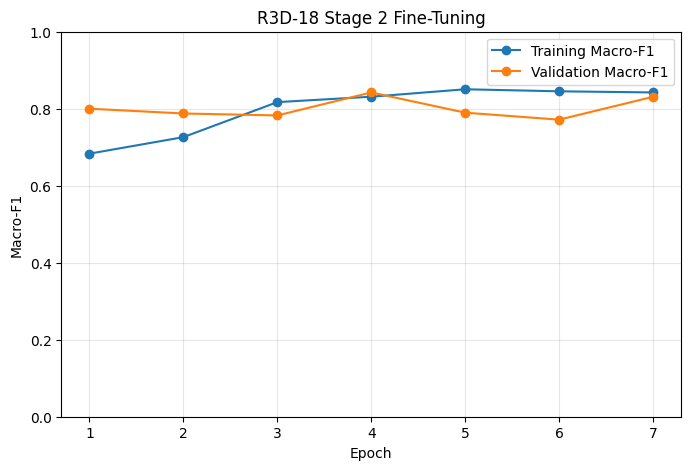

Stage 2 graph saved to: /content/drive/MyDrive/MotionMirror/results/model_comparison/r3d_18/stage2_f1_curve.png


In [ ]:
import matplotlib.pyplot as plt

# Use the actual number of completed epochs.
epochs_completed = range(
    1,
    len(stage2_history["train_f1"]) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_completed,
    stage2_history["train_f1"],
    marker="o",
    label="Training Macro-F1"
)

plt.plot(
    epochs_completed,
    stage2_history["val_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("R3D-18 Stage 2 Fine-Tuning")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)

STAGE2_PLOT_PATH = os.path.join(
    MODEL_RESULTS_DIR,
    "stage2_f1_curve.png"
)

plt.savefig(
    STAGE2_PLOT_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Stage 2 graph saved to:", STAGE2_PLOT_PATH)

In [ ]:
import gc

# The completed R3D checkpoints have already been saved.
# Release the previous model's GPU memory before loading MC3.

del model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Select the next architecture.
MODEL_NAME = "mc3_18"

MODEL_CONFIG = MODEL_CONFIGS[MODEL_NAME]

# Retrieve the preprocessing settings of MC3 pretrained weights.
PREPROCESS = MODEL_CONFIG["weights"].transforms()

NUM_FRAMES = MODEL_CONFIG["num_frames"]
FRAME_SIZE = PREPROCESS.crop_size[0]
BATCH_SIZE = MODEL_CONFIG["batch_size"]

# Keep checkpoint and evaluation files separate for every model.
MODEL_CHECKPOINT_DIR = os.path.join(
    CHECKPOINT_DIR,
    MODEL_NAME
)

MODEL_RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "model_comparison",
    MODEL_NAME
)

os.makedirs(MODEL_CHECKPOINT_DIR, exist_ok=True)
os.makedirs(MODEL_RESULTS_DIR, exist_ok=True)

print("Selected model:", MODEL_NAME)
print("Number of frames:", NUM_FRAMES)
print("Frame size:", FRAME_SIZE)
print("Batch size:", BATCH_SIZE)
print("Normalization mean:", PREPROCESS.mean)
print("Normalization std:", PREPROCESS.std)

Selected model: mc3_18
Number of frames: 16
Frame size: 112
Batch size: 4
Normalization mean: [0.43216, 0.394666, 0.37645]
Normalization std: [0.22803, 0.22145, 0.216989]


In [ ]:
# Recreate the training dataset using MC3 settings.
train_dataset = HMDBVideoDataset(
    dataframe=train_df,
    model_config=MODEL_CONFIG,
    training=True
)

# Validation uses deterministic preprocessing.
val_dataset = HMDBVideoDataset(
    dataframe=val_df,
    model_config=MODEL_CONFIG,
    training=False
)

# New generator for reproducible DataLoader shuffling.
data_loader_generator = torch.Generator()
data_loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    worker_init_fn=seed_worker,
    generator=data_loader_generator,
    persistent_workers=(NUM_WORKERS > 0)
)

val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    worker_init_fn=seed_worker,
    persistent_workers=(NUM_WORKERS > 0)
)

# Verify expected dataset sizes.
assert len(train_dataset) == 280
assert len(val_dataset) == 70

# Verify MC3 input dimensions.
sample_video, sample_label = train_dataset[0]

assert sample_video.shape == (
    3,
    NUM_FRAMES,
    FRAME_SIZE,
    FRAME_SIZE
)

print("Training videos:", len(train_dataset))
print("Validation videos:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Sample video shape:", sample_video.shape)

Training videos: 280
Validation videos: 70
Training batches: 70
Validation batches: 18
Sample video shape: torch.Size([3, 16, 112, 112])


In [ ]:
# Set random seeds for reproducibility.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)

# Load MC3-18 with pretrained Kinetics-400 weights.
model = mc3_18(
    weights=MODEL_CONFIG["weights"]
)

# Freeze the entire pretrained backbone.
for parameter in model.parameters():
    parameter.requires_grad = False

# Replace the 400-class classifier with five outputs.
CLASSIFIER_INPUT_FEATURES = model.fc.in_features

model.fc = nn.Sequential(
    nn.Dropout(p=0.50),
    nn.Linear(
        CLASSIFIER_INPUT_FEATURES,
        NUM_CLASSES
    )
)

model = model.to(DEVICE)

# Create model-specific checkpoint and history paths.
STAGE1_CHECKPOINT_PATH = os.path.join(
    MODEL_CHECKPOINT_DIR,
    "stage1_best.pth"
)

STAGE1_HISTORY_PATH = os.path.join(
    MODEL_RESULTS_DIR,
    "stage1_history.csv"
)

# Optimize only the trainable classifier parameters.
optimizer = AdamW(
    [
        parameter
        for parameter in model.parameters()
        if parameter.requires_grad
    ],
    lr=STAGE1_LEARNING_RATE,
    weight_decay=STAGE1_WEIGHT_DECAY
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

# Verify the output shape.
model.eval()

sample_batch = sample_video.unsqueeze(0).to(DEVICE)

with torch.inference_mode():
    sample_logits = model(sample_batch)

assert sample_logits.shape == (1, NUM_CLASSES)

print("Model:", MODEL_NAME)
print("Classifier:", model.fc)
print("Input shape:", sample_batch.shape)
print("Output shape:", sample_logits.shape)

print(
    "Trainable parameters:",
    sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )
)

print("Stage 1 checkpoint:", STAGE1_CHECKPOINT_PATH)

Downloading: "https://download.pytorch.org/models/mc3_18-a90a0ba3.pth" to /root/.cache/torch/hub/checkpoints/mc3_18-a90a0ba3.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 107MB/s]


Model: mc3_18
Classifier: Sequential(
  (0): Dropout(p=0.5, inplace=False)
  (1): Linear(in_features=512, out_features=5, bias=True)
)
Input shape: torch.Size([1, 3, 16, 112, 112])
Output shape: torch.Size([1, 5])
Trainable parameters: 2565
Stage 1 checkpoint: /content/drive/MyDrive/MotionMirror/checkpoints/mc3_18/stage1_best.pth


In [ ]:
# Stage 1 trains only the new classification head.

stage1_history = fit_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=DEVICE,
    model_name=MODEL_NAME,
    model_config=MODEL_CONFIG,
    trainable_modules=("fc",),
    num_epochs=STAGE1_EPOCHS,
    patience=EARLY_STOPPING_PATIENCE,
    checkpoint_path=STAGE1_CHECKPOINT_PATH,
    history_path=STAGE1_HISTORY_PATH,
    stage="stage1"
)

# Restore the best Stage 1 checkpoint.
stage1_checkpoint = torch.load(
    STAGE1_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(
    stage1_checkpoint["model_state_dict"]
)

print("Best Stage 1 epoch:", stage1_checkpoint["epoch"])

print(
    "Best Stage 1 validation macro-F1:",
    f"{stage1_checkpoint['val_f1']:.4f}"
)


mc3_18 - stage1 - Epoch 1/8


Training:   0%|          | 0/70 [00:00<?, ?it/s]

Validation:   0%|          | 0/18 [00:00<?, ?it/s]

Train Loss: 1.6083 | Train Acc: 0.2929 | Train F1: 0.2936
Val Loss:   1.2219 | Val Acc:   0.5857 | Val F1: 0.5580
Best checkpoint saved (Val F1: 0.5580)

mc3_18 - stage1 - Epoch 2/8


Training:   0%|          | 0/70 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/18 [00:00<?, ?it/s]

Train Loss: 0.5660 | Train Acc: 0.7821 | Train F1: 0.7810
Val Loss:   0.5409 | Val Acc:   0.8143 | Val F1: 0.8183
Best checkpoint saved (Val F1: 0.8183)

mc3_18 - stage1 - Epoch 8/8


Training:   0%|          | 0/70 [00:00<?, ?it/s]

Validation:   0%|          | 0/18 [00:00<?, ?it/s]

Train Loss: 0.4925 | Train Acc: 0.8143 | Train F1: 0.8149
Val Loss:   0.5520 | Val Acc:   0.7857 | Val F1: 0.7948
No improvement for 1 epoch(s).

Best stage1 validation F1: 0.8183
Best Stage 1 epoch: 7
Best Stage 1 validation macro-F1: 0.8183


In [ ]:
# Restore the best Stage 1 weights before fine-tuning.
model.load_state_dict(
    stage1_checkpoint["model_state_dict"]
)

# Freeze all parameters again.
for parameter in model.parameters():
    parameter.requires_grad = False

# Unfreeze the final backbone block.
for parameter in model.layer4.parameters():
    parameter.requires_grad = True

# Unfreeze the five-class classifier.
for parameter in model.fc.parameters():
    parameter.requires_grad = True

# Separate Stage 2 checkpoint and history files.
STAGE2_CHECKPOINT_PATH = os.path.join(
    MODEL_CHECKPOINT_DIR,
    "stage2_best.pth"
)

STAGE2_HISTORY_PATH = os.path.join(
    MODEL_RESULTS_DIR,
    "stage2_history.csv"
)

# Reuse the Stage 2 hyperparameters from R3D.
stage2_optimizer = AdamW(
    [
        {
            "params": model.layer4.parameters(),
            "lr": STAGE2_BACKBONE_LEARNING_RATE
        },
        {
            "params": model.fc.parameters(),
            "lr": STAGE2_CLASSIFIER_LEARNING_RATE
        }
    ],
    weight_decay=STAGE2_WEIGHT_DECAY
)

stage2_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

print("Stage 2 model:", MODEL_NAME)

print(
    "Trainable parameters:",
    sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )
)

print("Stage 2 checkpoint:", STAGE2_CHECKPOINT_PATH)

Stage 2 model: mc3_18
Trainable parameters: 8396293
Stage 2 checkpoint: /content/drive/MyDrive/MotionMirror/checkpoints/mc3_18/stage2_best.pth


In [ ]:
# Fine-tune layer4 and the five-class classifier.

stage2_history = fit_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=stage2_optimizer,
    scaler=stage2_scaler,
    device=DEVICE,
    model_name=MODEL_NAME,
    model_config=MODEL_CONFIG,
    trainable_modules=("layer4", "fc"),
    num_epochs=STAGE2_EPOCHS,
    patience=STAGE2_EARLY_STOPPING_PATIENCE,
    checkpoint_path=STAGE2_CHECKPOINT_PATH,
    history_path=STAGE2_HISTORY_PATH,
    stage="stage2"
)

stage2_checkpoint = torch.load(
    STAGE2_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

print("Best Stage 2 epoch:", stage2_checkpoint["epoch"])

print(
    "Best Stage 2 validation macro-F1:",
    f"{stage2_checkpoint['val_f1']:.4f}"
)


mc3_18 - stage2 - Epoch 1/8


Training:   0%|          | 0/70 [00:00<?, ?it/s]

Validation:   0%|          | 0/18 [00:00<?, ?it/s]

Train Loss: 0.7747 | Train Acc: 0.7143 | Train F1: 0.7156
Val Loss:   0.5225 | Val Acc:   0.7714 | Val F1: 0.7793
Best checkpoint saved (Val F1: 0.7793)

mc3_18 - stage2 - Epoch 2/8


Training:   0%|          | 0/70 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/18 [00:00<?, ?it/s]

Train Loss: 0.6108 | Train Acc: 0.7857 | Train F1: 0.7836
Val Loss:   0.4594 | Val Acc:   0.7857 | Val F1: 0.7913
No improvement for 2 epoch(s).

mc3_18 - stage2 - Epoch 5/8


Training:   0%|          | 0/70 [00:00<?, ?it/s]

Validation:   0%|          | 0/18 [00:00<?, ?it/s]

Train Loss: 0.5309 | Train Acc: 0.8286 | Train F1: 0.8269
Val Loss:   0.4546 | Val Acc:   0.8143 | Val F1: 0.8167
No improvement for 3 epoch(s).
Early stopping triggered.

Best stage2 validation F1: 0.8186
Best Stage 2 epoch: 2
Best Stage 2 validation macro-F1: 0.8186


In [ ]:
# Compare the best validation macro-F1 values.
stage1_f1 = stage1_checkpoint["val_f1"]
stage2_f1 = stage2_checkpoint["val_f1"]

print("Stage 1 macro-F1:", f"{stage1_f1:.4f}")
print("Stage 2 macro-F1:", f"{stage2_f1:.4f}")

if stage2_f1 > stage1_f1:
    BEST_STAGE = "stage2"
    BEST_CHECKPOINT_PATH = STAGE2_CHECKPOINT_PATH
    best_checkpoint = stage2_checkpoint
else:
    BEST_STAGE = "stage1"
    BEST_CHECKPOINT_PATH = STAGE1_CHECKPOINT_PATH
    best_checkpoint = stage1_checkpoint

# Save the selected checkpoint under a stable filename.
FINAL_MC3_CHECKPOINT_PATH = os.path.join(
    MODEL_CHECKPOINT_DIR,
    "best.pth"
)

shutil.copy2(
    BEST_CHECKPOINT_PATH,
    FINAL_MC3_CHECKPOINT_PATH
)

# Load the selected model.
model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model.eval()

# Save validation metrics for later comparison.
validation_summary = pd.DataFrame([
    {
        "model": MODEL_NAME,
        "selected_stage": BEST_STAGE,
        "val_accuracy": best_checkpoint["val_accuracy"],
        "val_macro_f1": best_checkpoint["val_f1"],
        "checkpoint_path": FINAL_MC3_CHECKPOINT_PATH
    }
])

VALIDATION_SUMMARY_PATH = os.path.join(
    MODEL_RESULTS_DIR,
    "validation_summary.csv"
)

validation_summary.to_csv(
    VALIDATION_SUMMARY_PATH,
    index=False
)

print("Selected stage:", BEST_STAGE)
print("Best validation F1:", f"{best_checkpoint['val_f1']:.4f}")
print("Final checkpoint:", FINAL_MC3_CHECKPOINT_PATH)

display(validation_summary)

Stage 1 macro-F1: 0.8183
Stage 2 macro-F1: 0.8186
Selected stage: stage2
Best validation F1: 0.8186
Final checkpoint: /content/drive/MyDrive/MotionMirror/checkpoints/mc3_18/best.pth


,model,selected_stage,val_accuracy,val_macro_f1,checkpoint_path
0,mc3_18,stage2,0.814286,0.818589,/content/drive/MyDrive/MotionMirror/checkpoint...


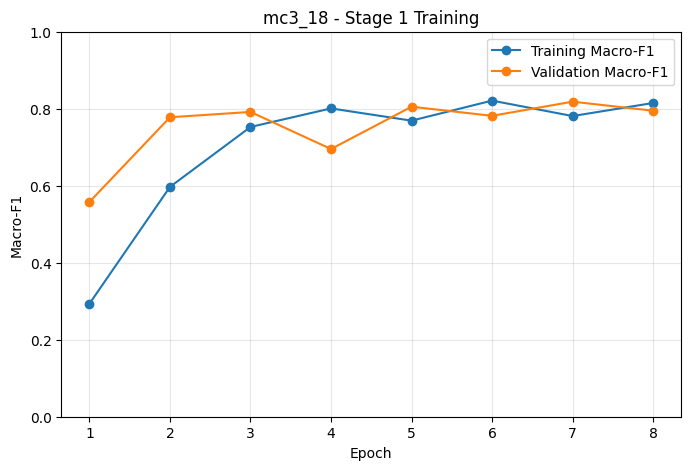

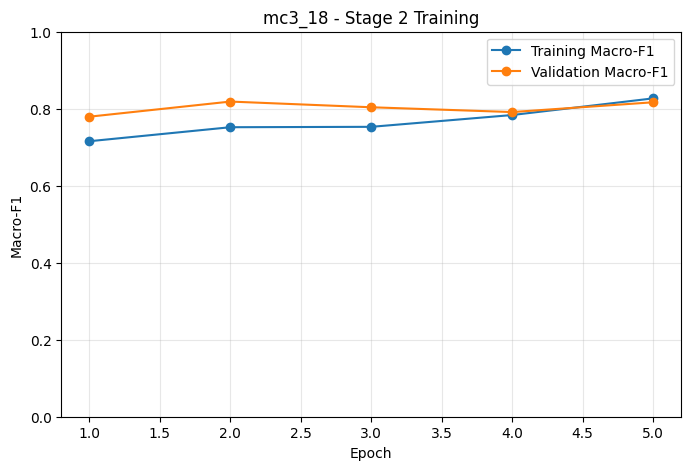

In [ ]:
import matplotlib.pyplot as plt

def plot_training_history(history, model_name, stage, save_path):

    epochs = range(
        1,
        len(history["train_f1"]) + 1
    )

    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs,
        history["train_f1"],
        marker="o",
        label="Training Macro-F1"
    )

    plt.plot(
        epochs,
        history["val_f1"],
        marker="o",
        label="Validation Macro-F1"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Macro-F1")
    plt.title(f"{model_name} - {stage} Training")
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(alpha=0.3)

    plt.savefig(
        save_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()


# Save Stage 1 graph.
plot_training_history(
    history=stage1_history,
    model_name=MODEL_NAME,
    stage="Stage 1",
    save_path=os.path.join(
        MODEL_RESULTS_DIR,
        "stage1_f1_curve.png"
    )
)

# Save Stage 2 graph.
plot_training_history(
    history=stage2_history,
    model_name=MODEL_NAME,
    stage="Stage 2",
    save_path=os.path.join(
        MODEL_RESULTS_DIR,
        "stage2_f1_curve.png"
    )
)

In [ ]:
import gc

# Release references to the completed MC3 model,
# its optimizers, and earlier batches.
del model, optimizer, stage2_optimizer
del scaler, stage2_scaler
del sample_batch, sample_logits
del train_loader, val_loader
del train_dataset, val_dataset
del stage1_checkpoint, stage2_checkpoint, best_checkpoint

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Select our final architecture.
MODEL_NAME = "mvit_v2_s"

# Use a conservative batch size for the transformer.
MODEL_CONFIGS[MODEL_NAME]["batch_size"] = 1

MODEL_CONFIG = MODEL_CONFIGS[MODEL_NAME]

# Retrieve MViT's official pretrained preprocessing.
PREPROCESS = MODEL_CONFIG["weights"].transforms()

NUM_FRAMES = MODEL_CONFIG["num_frames"]
FRAME_SIZE = PREPROCESS.crop_size[0]
BATCH_SIZE = MODEL_CONFIG["batch_size"]

# Keep checkpoints and results separate from the CNN models.
MODEL_CHECKPOINT_DIR = os.path.join(
    CHECKPOINT_DIR,
    MODEL_NAME
)

MODEL_RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "5class",
    "model_comparison",
    MODEL_NAME
)

os.makedirs(MODEL_CHECKPOINT_DIR, exist_ok=True)
os.makedirs(MODEL_RESULTS_DIR, exist_ok=True)

assert NUM_FRAMES == 16
assert FRAME_SIZE == 224

print("Model:", MODEL_NAME)
print("Frames:", NUM_FRAMES)
print("Frame size:", FRAME_SIZE)
print("Batch size:", BATCH_SIZE)
print("Resize size:", PREPROCESS.resize_size)
print("Normalization mean:", PREPROCESS.mean)
print("Normalization std:", PREPROCESS.std)

Model: mvit_v2_s
Frames: 16
Frame size: 224
Batch size: 1
Resize size: [256]
Normalization mean: [0.45, 0.45, 0.45]
Normalization std: [0.225, 0.225, 0.225]


In [ ]:
# Create datasets using MViT preprocessing settings.
train_dataset = HMDBVideoDataset(
    dataframe=train_df,
    model_config=MODEL_CONFIG,
    training=True
)

val_dataset = HMDBVideoDataset(
    dataframe=val_df,
    model_config=MODEL_CONFIG,
    training=False
)

# Use the same random seed as the previous models.
data_loader_generator = torch.Generator()
data_loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    worker_init_fn=seed_worker,
    generator=data_loader_generator,
    persistent_workers=(NUM_WORKERS > 0)
)

val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    worker_init_fn=seed_worker,
    persistent_workers=(NUM_WORKERS > 0)
)

# Verify the dataset and input dimensions.
assert len(train_dataset) == 280
assert len(val_dataset) == 70

sample_video, sample_label = train_dataset[0]

assert sample_video.shape == (
    3,
    NUM_FRAMES,
    FRAME_SIZE,
    FRAME_SIZE
)

print("Training videos:", len(train_dataset))
print("Validation videos:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Sample shape:", sample_video.shape)
print("Sample action:", INDEX_TO_CLASS[sample_label])

Training videos: 280
Validation videos: 70
Training batches: 280
Validation batches: 70
Sample shape: torch.Size([3, 16, 224, 224])
Sample action: pushup


In [ ]:
# Initialize random seeds.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)

# Load Kinetics-400 pretrained MViT-V2-S.
model = mvit_v2_s(
    weights=MODEL_CONFIG["weights"]
)

# Freeze the entire pretrained transformer.
for parameter in model.parameters():
    parameter.requires_grad = False

# Replace the original 400-class classification head.
CLASSIFIER_INPUT_FEATURES = model.head[-1].in_features

model.head = nn.Sequential(
    nn.Dropout(p=0.50),
    nn.Linear(
        CLASSIFIER_INPUT_FEATURES,
        NUM_CLASSES
    )
)

model = model.to(DEVICE)

# Stage 1 checkpoint and history paths.
STAGE1_CHECKPOINT_PATH = os.path.join(
    MODEL_CHECKPOINT_DIR,
    "stage1_best.pth"
)

STAGE1_HISTORY_PATH = os.path.join(
    MODEL_RESULTS_DIR,
    "stage1_history.csv"
)

# Train only the new classifier during Stage 1.
optimizer = AdamW(
    model.head.parameters(),
    lr=STAGE1_LEARNING_RATE,
    weight_decay=STAGE1_WEIGHT_DECAY
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

# Verify that MViT produces five output logits.
model.eval()

with torch.inference_mode():

    with torch.autocast(
        device_type=DEVICE.type,
        dtype=torch.float16,
        enabled=USE_AMP
    ):

        sample_logits = model(
            sample_video.unsqueeze(0).to(DEVICE)
        )

assert sample_logits.shape == (1, NUM_CLASSES)

print("Model:", MODEL_NAME)
print("Classifier:", model.head)
print("Output shape:", sample_logits.shape)

print(
    "Trainable parameters:",
    sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )
)

print("Stage 1 checkpoint:", STAGE1_CHECKPOINT_PATH)

Downloading: "https://download.pytorch.org/models/mvit_v2_s-ae3be167.pth" to /root/.cache/torch/hub/checkpoints/mvit_v2_s-ae3be167.pth


100%|██████████| 132M/132M [00:01<00:00, 118MB/s]


Model: mvit_v2_s
Classifier: Sequential(
  (0): Dropout(p=0.5, inplace=False)
  (1): Linear(in_features=768, out_features=5, bias=True)
)
Output shape: torch.Size([1, 5])
Trainable parameters: 3845
Stage 1 checkpoint: /content/drive/MyDrive/MotionMirror/checkpoints/mvit_v2_s/stage1_best.pth


In [ ]:
# Train the five-class MViT classification head.

stage1_history = fit_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=DEVICE,
    model_name=MODEL_NAME,
    model_config=MODEL_CONFIG,
    trainable_modules=("head",),
    num_epochs=STAGE1_EPOCHS,
    patience=EARLY_STOPPING_PATIENCE,
    checkpoint_path=STAGE1_CHECKPOINT_PATH,
    history_path=STAGE1_HISTORY_PATH,
    stage="stage1"
)

# Restore the best Stage 1 checkpoint.
stage1_checkpoint = torch.load(
    STAGE1_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(
    stage1_checkpoint["model_state_dict"]
)

print("Best Stage 1 epoch:", stage1_checkpoint["epoch"])

print(
    "Best Stage 1 validation macro-F1:",
    f"{stage1_checkpoint['val_f1']:.4f}"
)


mvit_v2_s - stage1 - Epoch 1/8


Training:   0%|          | 0/280 [00:00<?, ?it/s]

Validation:   0%|          | 0/70 [00:00<?, ?it/s]

Train Loss: 0.8457 | Train Acc: 0.7357 | Train F1: 0.7315
Val Loss:   0.4739 | Val Acc:   0.9143 | Val F1: 0.9164
Best checkpoint saved (Val F1: 0.9164)

mvit_v2_s - stage1 - Epoch 2/8


Training:   0%|          | 0/280 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/70 [00:00<?, ?it/s]

Train Loss: 0.1694 | Train Acc: 0.9679 | Train F1: 0.9678
Val Loss:   0.2675 | Val Acc:   0.9143 | Val F1: 0.9179
No improvement for 2 epoch(s).

mvit_v2_s - stage1 - Epoch 7/8


Training:   0%|          | 0/280 [00:00<?, ?it/s]

Validation:   0%|          | 0/70 [00:00<?, ?it/s]

Train Loss: 0.1501 | Train Acc: 0.9643 | Train F1: 0.9644
Val Loss:   0.2395 | Val Acc:   0.9286 | Val F1: 0.9315
No improvement for 3 epoch(s).
Early stopping triggered.

Best stage1 validation F1: 0.9315
Best Stage 1 epoch: 4
Best Stage 1 validation macro-F1: 0.9315


In [ ]:
# Restore the best Stage 1 checkpoint.
model.load_state_dict(
    stage1_checkpoint["model_state_dict"]
)

# Freeze the complete transformer again.
for parameter in model.parameters():
    parameter.requires_grad = False

# Identify the final transformer block.
LAST_BLOCK_INDEX = len(model.blocks) - 1
LAST_BLOCK_NAME = f"blocks.{LAST_BLOCK_INDEX}"

# Unfreeze the final transformer block.
for parameter in model.blocks[-1].parameters():
    parameter.requires_grad = True

# Unfreeze the final normalization layer.
for parameter in model.norm.parameters():
    parameter.requires_grad = True

# Keep our five-class classifier trainable.
for parameter in model.head.parameters():
    parameter.requires_grad = True

# Save Stage 2 independently.
STAGE2_CHECKPOINT_PATH = os.path.join(
    MODEL_CHECKPOINT_DIR,
    "stage2_best.pth"
)

STAGE2_HISTORY_PATH = os.path.join(
    MODEL_RESULTS_DIR,
    "stage2_history.csv"
)

# Use lower learning rates for pretrained parameters.
stage2_optimizer = AdamW(
    [
        {
            "params": model.blocks[-1].parameters(),
            "lr": STAGE2_BACKBONE_LEARNING_RATE
        },
        {
            "params": model.norm.parameters(),
            "lr": STAGE2_BACKBONE_LEARNING_RATE
        },
        {
            "params": model.head.parameters(),
            "lr": STAGE2_CLASSIFIER_LEARNING_RATE
        }
    ],
    weight_decay=STAGE2_WEIGHT_DECAY
)

stage2_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

print("Final transformer block:", LAST_BLOCK_NAME)

print(
    "Trainable parameters:",
    sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )
)

print("Stage 2 checkpoint:", STAGE2_CHECKPOINT_PATH)

Final transformer block: blocks.15
Trainable parameters: 7105541
Stage 2 checkpoint: /content/drive/MyDrive/MotionMirror/checkpoints/mvit_v2_s/stage2_best.pth


In [ ]:
# Fine-tune the last transformer block,
# final normalization layer, and classifier.

stage2_history = fit_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=stage2_optimizer,
    scaler=stage2_scaler,
    device=DEVICE,
    model_name=MODEL_NAME,
    model_config=MODEL_CONFIG,
    trainable_modules=(
        LAST_BLOCK_NAME,
        "norm",
        "head"
    ),
    num_epochs=STAGE2_EPOCHS,
    patience=STAGE2_EARLY_STOPPING_PATIENCE,
    checkpoint_path=STAGE2_CHECKPOINT_PATH,
    history_path=STAGE2_HISTORY_PATH,
    stage="stage2"
)

stage2_checkpoint = torch.load(
    STAGE2_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

print("Best Stage 2 epoch:", stage2_checkpoint["epoch"])

print(
    "Best Stage 2 validation macro-F1:",
    f"{stage2_checkpoint['val_f1']:.4f}"
)


mvit_v2_s - stage2 - Epoch 1/8


Training:   0%|          | 0/280 [00:00<?, ?it/s]

Validation:   0%|          | 0/70 [00:00<?, ?it/s]

Train Loss: 0.2103 | Train Acc: 0.9500 | Train F1: 0.9502
Val Loss:   0.2610 | Val Acc:   0.9286 | Val F1: 0.9315
Best checkpoint saved (Val F1: 0.9315)

mvit_v2_s - stage2 - Epoch 2/8


Training:   0%|          | 0/280 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/70 [00:00<?, ?it/s]

Train Loss: 0.1560 | Train Acc: 0.9750 | Train F1: 0.9749
Val Loss:   0.2438 | Val Acc:   0.9286 | Val F1: 0.9315
No improvement for 2 epoch(s).

mvit_v2_s - stage2 - Epoch 4/8


Training:   0%|          | 0/280 [00:00<?, ?it/s]

Validation:   0%|          | 0/70 [00:00<?, ?it/s]

Train Loss: 0.1485 | Train Acc: 0.9679 | Train F1: 0.9679
Val Loss:   0.2384 | Val Acc:   0.9286 | Val F1: 0.9315
No improvement for 3 epoch(s).
Early stopping triggered.

Best stage2 validation F1: 0.9315
Best Stage 2 epoch: 1
Best Stage 2 validation macro-F1: 0.9315


In [ ]:
import shutil

stage1_f1 = float(stage1_checkpoint["val_f1"])
stage2_f1 = float(stage2_checkpoint["val_f1"])

print("Stage 1 validation F1:", f"{stage1_f1:.4f}")
print("Stage 2 validation F1:", f"{stage2_f1:.4f}")

if stage2_f1 > stage1_f1:

    BEST_STAGE = "stage2"
    BEST_CHECKPOINT_PATH = STAGE2_CHECKPOINT_PATH
    best_checkpoint = stage2_checkpoint

else:

    BEST_STAGE = "stage1"
    BEST_CHECKPOINT_PATH = STAGE1_CHECKPOINT_PATH
    best_checkpoint = stage1_checkpoint

# Save the selected checkpoint under one stable filename.
FINAL_MVIT_CHECKPOINT_PATH = os.path.join(
    MODEL_CHECKPOINT_DIR,
    "best.pth"
)

shutil.copy2(
    BEST_CHECKPOINT_PATH,
    FINAL_MVIT_CHECKPOINT_PATH
)

# Load the selected MViT weights.
model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model.eval()

# Save the validation summary.
validation_summary = pd.DataFrame([
    {
        "model": MODEL_NAME,
        "selected_stage": BEST_STAGE,
        "val_accuracy": float(
            best_checkpoint["val_accuracy"]
        ),
        "val_macro_f1": float(
            best_checkpoint["val_f1"]
        ),
        "checkpoint_path": FINAL_MVIT_CHECKPOINT_PATH
    }
])

VALIDATION_SUMMARY_PATH = os.path.join(
    MODEL_RESULTS_DIR,
    "validation_summary.csv"
)

validation_summary.to_csv(
    VALIDATION_SUMMARY_PATH,
    index=False
)

print("Selected stage:", BEST_STAGE)
print(
    "Best validation F1:",
    f"{best_checkpoint['val_f1']:.4f}"
)
print("Final checkpoint:", FINAL_MVIT_CHECKPOINT_PATH)

display(validation_summary)

Stage 1 validation F1: 0.9315
Stage 2 validation F1: 0.9315
Selected stage: stage1
Best validation F1: 0.9315
Final checkpoint: /content/drive/MyDrive/MotionMirror/checkpoints/mvit_v2_s/best.pth


,model,selected_stage,val_accuracy,val_macro_f1,checkpoint_path
0,mvit_v2_s,stage1,0.928571,0.93152,/content/drive/MyDrive/MotionMirror/checkpoint...


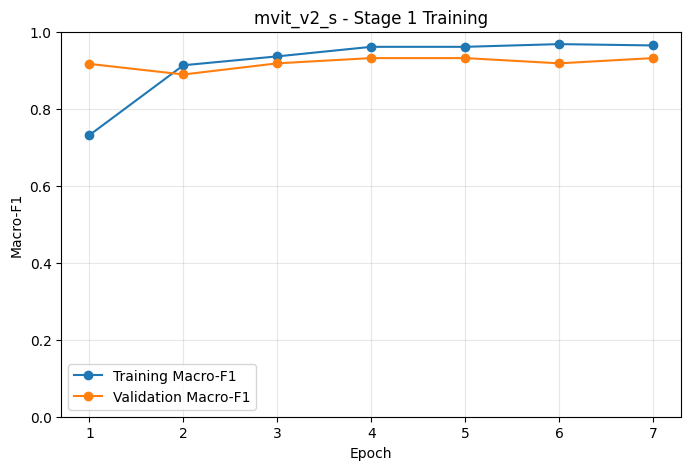

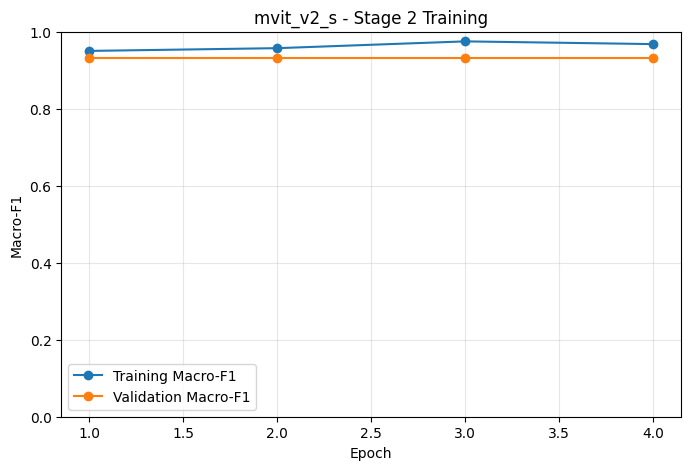

In [ ]:
# Plot and save Stage 1 results.
plot_training_history(
    history=stage1_history,
    model_name=MODEL_NAME,
    stage="Stage 1",
    save_path=os.path.join(
        MODEL_RESULTS_DIR,
        "stage1_f1_curve.png"
    )
)

# Plot and save Stage 2 results.
plot_training_history(
    history=stage2_history,
    model_name=MODEL_NAME,
    stage="Stage 2",
    save_path=os.path.join(
        MODEL_RESULTS_DIR,
        "stage2_f1_curve.png"
    )
)

In [ ]:
import gc
import time
import matplotlib.pyplot as plt

from torchvision.models.video import (
    r2plus1d_18,
    R2Plus1D_18_Weights
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Create a separate folder for final evaluation.
FINAL_EVALUATION_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "5class",
    "final_evaluation"
)

os.makedirs(FINAL_EVALUATION_DIR, exist_ok=True)

# Register each architecture, pretrained preprocessing,
# final checkpoint, and evaluation batch size.
EVALUATION_MODELS = {
    "r2plus1d_18": {
        "builder": r2plus1d_18,
        "weights": R2Plus1D_18_Weights.KINETICS400_V1,
        "head": "fc",
        "batch_size": 4,
        "checkpoint_path": BASELINE_CHECKPOINT_PATH
    },
    "r3d_18": {
        "builder": r3d_18,
        "weights": R3D_18_Weights.KINETICS400_V1,
        "head": "fc",
        "batch_size": 4,
        "checkpoint_path": os.path.join(
            CHECKPOINT_DIR, "r3d_18", "best.pth"
        )
    },
    "mc3_18": {
        "builder": mc3_18,
        "weights": MC3_18_Weights.KINETICS400_V1,
        "head": "fc",
        "batch_size": 4,
        "checkpoint_path": os.path.join(
            CHECKPOINT_DIR, "mc3_18", "best.pth"
        )
    },
    "mvit_v2_s": {
        "builder": mvit_v2_s,
        "weights": MViT_V2_S_Weights.KINETICS400_V1,
        "head": "head",
        "batch_size": 1,
        "checkpoint_path": os.path.join(
            CHECKPOINT_DIR, "mvit_v2_s", "best.pth"
        )
    }
}

validation_records = []

# Inspect checkpoint metadata without running the test set.
for model_name, specification in EVALUATION_MODELS.items():

    checkpoint_path = specification["checkpoint_path"]

    if not os.path.isfile(checkpoint_path):
        raise FileNotFoundError(checkpoint_path)

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    # Verify that label indices are identical for all models.
    assert checkpoint["class_to_index"] == CLASS_TO_INDEX, (
        f"Class mapping mismatch for {model_name}"
    )

    preprocess = specification["weights"].transforms()

    # Verify compatibility with each architecture.
    assert checkpoint["num_frames"] == 16
    assert checkpoint["frame_size"] == preprocess.crop_size[0]

    assert np.isclose(
        checkpoint["temporal_window_seconds"],
        2.0
    ), f"Temporal sampling mismatch for {model_name}"

    validation_records.append({
        "model": model_name,
        "val_accuracy": float(checkpoint["val_accuracy"]),
        "val_macro_f1": float(checkpoint["val_f1"]),
        "checkpoint_path": checkpoint_path
    })

validation_df = pd.DataFrame(validation_records)

del checkpoint

print("All four checkpoints verified.")
display(validation_df)

All four checkpoints verified.


,model,val_accuracy,val_macro_f1,checkpoint_path
0,r2plus1d_18,0.900000,0.900278,/content/drive/MyDrive/MotionMirror/checkpoint...
1,r3d_18,0.842857,0.842277,/content/drive/MyDrive/MotionMirror/checkpoint...
2,mc3_18,0.814286,0.818589,/content/drive/MyDrive/MotionMirror/checkpoint...
3,mvit_v2_s,0.928571,0.931520,/content/drive/MyDrive/MotionMirror/checkpoint...


In [ ]:
# Select our initial deployment candidate without using test scores.
validation_ranked_df = (
    validation_df
    .sort_values(
        "val_macro_f1",
        ascending=False,
        kind="stable"
    )
    .reset_index(drop=True)
)

DEPLOYMENT_MODEL_NAME = validation_ranked_df.loc[
    0, "model"
]

DEPLOYMENT_CHECKPOINT_PATH = validation_ranked_df.loc[
    0, "checkpoint_path"
]

VALIDATION_RANKING_PATH = os.path.join(
    FINAL_EVALUATION_DIR,
    "validation_model_ranking.csv"
)

validation_ranked_df.to_csv(
    VALIDATION_RANKING_PATH,
    index=False
)

print("Validation ranking:")
display(validation_ranked_df)

print("Initial deployment candidate:", DEPLOYMENT_MODEL_NAME)
print("Checkpoint:", DEPLOYMENT_CHECKPOINT_PATH)

Validation ranking:


,model,val_accuracy,val_macro_f1,checkpoint_path
0,mvit_v2_s,0.928571,0.931520,/content/drive/MyDrive/MotionMirror/checkpoint...
1,r2plus1d_18,0.900000,0.900278,/content/drive/MyDrive/MotionMirror/checkpoint...
2,r3d_18,0.842857,0.842277,/content/drive/MyDrive/MotionMirror/checkpoint...
3,mc3_18,0.814286,0.818589,/content/drive/MyDrive/MotionMirror/checkpoint...


Initial deployment candidate: mvit_v2_s
Checkpoint: /content/drive/MyDrive/MotionMirror/checkpoints/mvit_v2_s/best.pth


In [ ]:
def build_evaluation_model(model_name, specification):

    # Create the architecture without downloading weights.
    evaluation_model = specification["builder"](
        weights=None
    )

    # Replace the original 400-class head with five outputs.
    if specification["head"] == "fc":

        input_features = evaluation_model.fc.in_features

        evaluation_model.fc = nn.Sequential(
            nn.Dropout(p=0.50),
            nn.Linear(input_features, NUM_CLASSES)
        )

    else:

        input_features = evaluation_model.head[-1].in_features

        evaluation_model.head = nn.Sequential(
            nn.Dropout(p=0.50),
            nn.Linear(input_features, NUM_CLASSES)
        )

    return evaluation_model


def evaluate_test_videos(
    evaluation_model,
    test_loader,
    device
):

    evaluation_model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    # No gradients are needed for final evaluation.
    with torch.inference_mode():

        for videos, labels in tqdm(
            test_loader,
            desc="Final test evaluation"
        ):

            videos = videos.to(
                device,
                non_blocking=True
            )

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=USE_AMP
            ):

                logits = evaluation_model(videos)

            probabilities = torch.softmax(
                logits.float(),
                dim=1
            ).cpu()

            predictions = probabilities.argmax(dim=1)

            all_labels.extend(labels.tolist())

            all_predictions.extend(
                predictions.tolist()
            )

            all_probabilities.extend(
                probabilities.tolist()
            )

    return (
        all_labels,
        all_predictions,
        all_probabilities
    )


def measure_inference_latency(
    evaluation_model,
    test_dataset,
    device
):

    # Benchmark model execution on one preprocessed video.
    # Video decoding and preprocessing are excluded.
    sample_video, _ = test_dataset[0]

    sample_input = sample_video.unsqueeze(0).to(device)

    evaluation_model.eval()

    latencies = []

    with torch.inference_mode():

        # Warm up the model before measuring.
        for _ in range(3):

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                evaluation_model(sample_input)

        if device.type == "cuda":
            torch.cuda.synchronize()

        # Measure ten forward passes.
        for _ in range(10):

            if device.type == "cuda":
                torch.cuda.synchronize()

            start_time = time.perf_counter()

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                evaluation_model(sample_input)

            if device.type == "cuda":
                torch.cuda.synchronize()

            elapsed = time.perf_counter() - start_time

            latencies.append(elapsed * 1000)

    return float(np.median(latencies))


Evaluating r2plus1d_18


Final test evaluation:   0%|          | 0/38 [00:00<?, ?it/s]

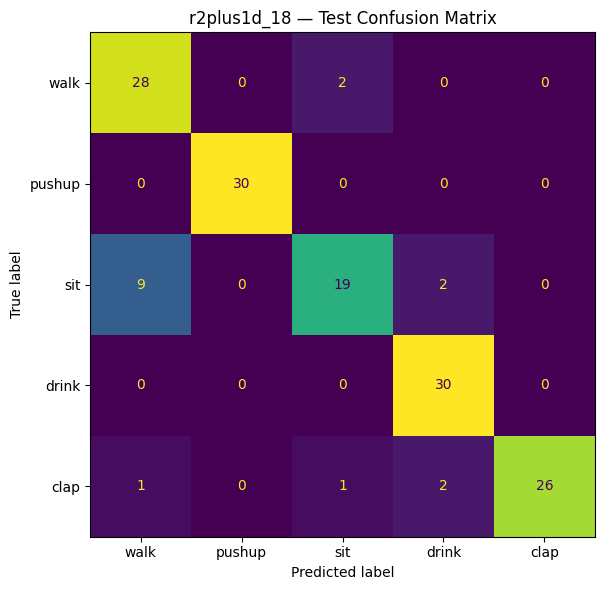

r2plus1d_18: Accuracy=0.8867, Macro-F1=0.8841

Evaluating r3d_18


Final test evaluation:   0%|          | 0/38 [00:00<?, ?it/s]

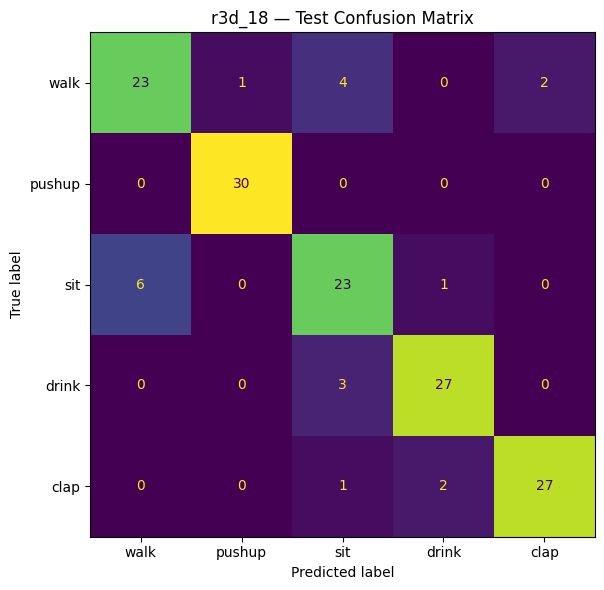

r3d_18: Accuracy=0.8667, Macro-F1=0.8665

Evaluating mc3_18


Final test evaluation:   0%|          | 0/38 [00:00<?, ?it/s]

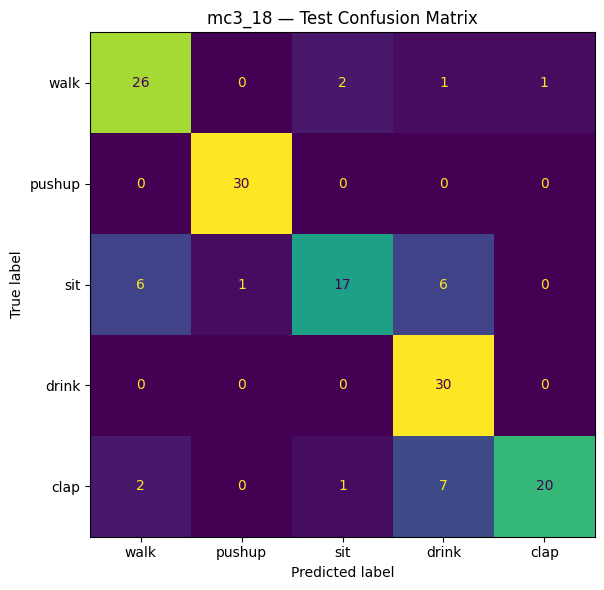

mc3_18: Accuracy=0.8200, Macro-F1=0.8142

Evaluating mvit_v2_s


Final test evaluation:   0%|          | 0/150 [00:00<?, ?it/s]

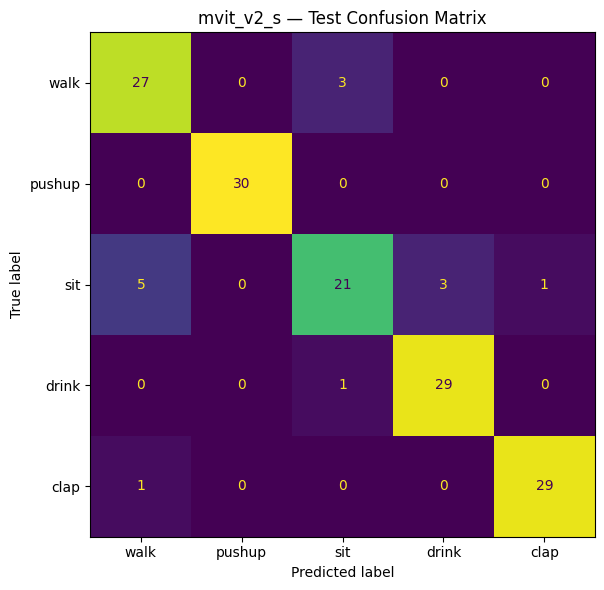

mvit_v2_s: Accuracy=0.9067, Macro-F1=0.9046


,model,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,parameters_millions,parameter_memory_mb,forward_latency_ms,val_macro_f1
0,mvit_v2_s,0.906667,0.906220,0.906667,0.904586,34.233989,130.592304,57.852503,0.931520
1,r2plus1d_18,0.886667,0.896566,0.886667,0.884074,31.302690,119.410286,17.705355,0.900278
2,r3d_18,0.866667,0.866763,0.866667,0.866524,33.168837,126.529072,13.184296,0.842277
3,mc3_18,0.820000,0.843329,0.820000,0.814246,11.492805,43.841572,13.863779,0.818589


Final comparison saved to: /content/drive/MyDrive/MotionMirror/results/5class/final_evaluation/four_model_comparison.csv


In [ ]:
# Release the completed MViT training model and optimizers.
del model, optimizer, stage2_optimizer
del scaler, stage2_scaler

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# The final test set must contain exactly 30 videos per class.
assert len(test_df) == 150

assert all(
    test_df.groupby("action").size() == 30
)

comparison_records = []

for model_name, specification in EVALUATION_MODELS.items():

    print(f"\nEvaluating {model_name}")

    # Load the model-specific checkpoint on CPU.
    checkpoint = torch.load(
        specification["checkpoint_path"],
        map_location="cpu",
        weights_only=True
    )

    # Restore the temporal settings saved during training.
    evaluation_config = {
        "weights": specification["weights"],
        "num_frames": checkpoint["num_frames"],
        "temporal_window_seconds": checkpoint[
            "temporal_window_seconds"
        ]
    }

    # Create the model-specific test dataset.
    test_dataset = HMDBVideoDataset(
        dataframe=test_df,
        model_config=evaluation_config,
        training=False
    )

    # Keep the test video order unchanged.
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=specification["batch_size"],
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
        worker_init_fn=seed_worker,
        persistent_workers=False
    )

    # Reconstruct the trained five-class architecture.
    evaluation_model = build_evaluation_model(
        model_name,
        specification
    )

    # Restore the selected trained parameters.
    evaluation_model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    evaluation_model = evaluation_model.to(DEVICE)
    evaluation_model.eval()

    # Evaluate all 150 test videos.
    (
        test_labels,
        test_predictions,
        test_probabilities
    ) = evaluate_test_videos(
        evaluation_model,
        test_loader,
        DEVICE
    )

    # Confirm predictions correspond to the expected rows.
    assert test_labels == test_df["label"].astype(int).tolist()

    assert len(test_predictions) == 150

    # Calculate the main classification metrics.
    test_accuracy = accuracy_score(
        test_labels,
        test_predictions
    )

    test_precision = precision_score(
        test_labels,
        test_predictions,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    test_recall = recall_score(
        test_labels,
        test_predictions,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    test_f1 = f1_score(
        test_labels,
        test_predictions,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    # Save outputs in a model-specific directory.
    MODEL_EVALUATION_DIR = os.path.join(
        FINAL_EVALUATION_DIR,
        model_name
    )

    os.makedirs(
        MODEL_EVALUATION_DIR,
        exist_ok=True
    )

    # Save every video prediction and probability.
    predictions_df = test_df[
        ["video_path", "video_name", "action", "label"]
    ].copy()

    predictions_df["predicted_label"] = test_predictions

    predictions_df["predicted_action"] = [
        INDEX_TO_CLASS[index]
        for index in test_predictions
    ]

    predictions_df["correct"] = (
        predictions_df["label"]
        == predictions_df["predicted_label"]
    )

    for class_index, action in INDEX_TO_CLASS.items():

        predictions_df[f"prob_{action}"] = [
            probabilities[class_index]
            for probabilities in test_probabilities
        ]

    predictions_df.to_csv(
        os.path.join(
            MODEL_EVALUATION_DIR,
            "test_predictions.csv"
        ),
        index=False
    )

    # Create and save the per-class classification report.
    report = classification_report(
        test_labels,
        test_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=SELECTED_CLASSES,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    report_df.to_csv(
        os.path.join(
            MODEL_EVALUATION_DIR,
            "classification_report.csv"
        )
    )

    # Generate the confusion matrix.
    cm = confusion_matrix(
        test_labels,
        test_predictions,
        labels=list(range(NUM_CLASSES))
    )

    cm_df = pd.DataFrame(
        cm,
        index=SELECTED_CLASSES,
        columns=SELECTED_CLASSES
    )

    cm_df.to_csv(
        os.path.join(
            MODEL_EVALUATION_DIR,
            "confusion_matrix.csv"
        )
    )

    fig, ax = plt.subplots(figsize=(7, 6))

    matrix_display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=SELECTED_CLASSES
    )

    matrix_display.plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{model_name} — Test Confusion Matrix")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            MODEL_EVALUATION_DIR,
            "confusion_matrix.png"
        ),
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    # Measure batch-size-1 model-forward latency.
    latency_ms = measure_inference_latency(
        evaluation_model,
        test_dataset,
        DEVICE
    )

    # Measure model parameters and parameter storage.
    parameter_count = sum(
        parameter.numel()
        for parameter in evaluation_model.parameters()
    )

    parameter_memory_mb = sum(
        parameter.numel() * parameter.element_size()
        for parameter in evaluation_model.parameters()
    ) / (1024 ** 2)

    comparison_records.append({
        "model": model_name,
        "test_accuracy": float(test_accuracy),
        "test_macro_precision": float(test_precision),
        "test_macro_recall": float(test_recall),
        "test_macro_f1": float(test_f1),
        "parameters_millions": parameter_count / 1e6,
        "parameter_memory_mb": parameter_memory_mb,
        "forward_latency_ms": latency_ms
    })

    print(
        f"{model_name}: "
        f"Accuracy={test_accuracy:.4f}, "
        f"Macro-F1={test_f1:.4f}"
    )

    # Free the model before loading the next architecture.
    del evaluation_model
    del checkpoint
    del test_loader
    del test_dataset

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# Combine the recorded metrics from all four models.
comparison_df = pd.DataFrame(comparison_records)

# Add the previously recorded validation results.
comparison_df = comparison_df.merge(
    validation_df[
        ["model", "val_macro_f1"]
    ],
    on="model",
    how="left"
)

# Sort for display only; do not change deployment selection.
comparison_df = (
    comparison_df
    .sort_values(
        "test_macro_f1",
        ascending=False
    )
    .reset_index(drop=True)
)

FINAL_COMPARISON_PATH = os.path.join(
    FINAL_EVALUATION_DIR,
    "four_model_comparison.csv"
)

comparison_df.to_csv(
    FINAL_COMPARISON_PATH,
    index=False
)

display(comparison_df)

print("Final comparison saved to:", FINAL_COMPARISON_PATH)

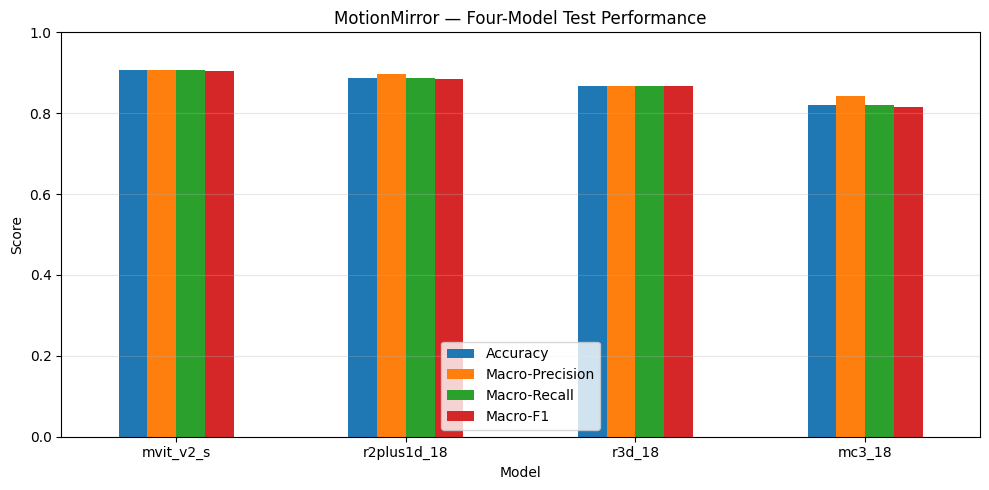

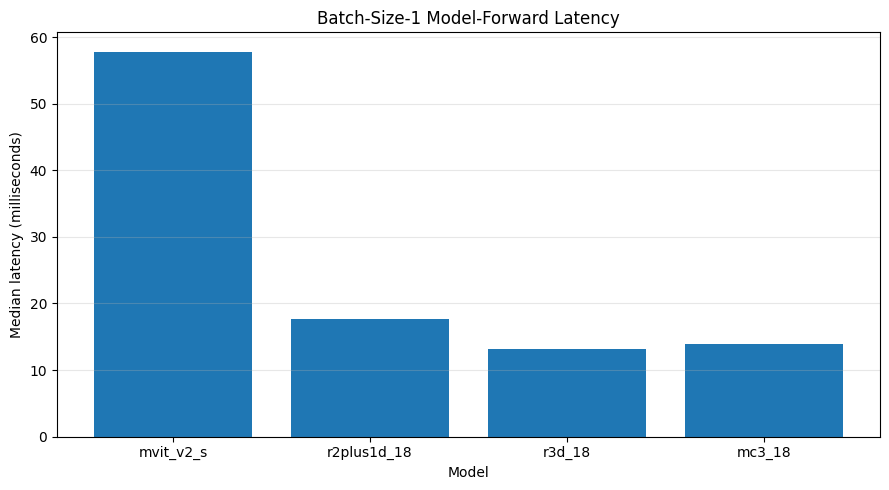

In [ ]:
# Compare all four models using their measured test metrics.

plot_df = comparison_df.set_index("model")

fig, ax = plt.subplots(figsize=(10, 5))

plot_df[
    [
        "test_accuracy",
        "test_macro_precision",
        "test_macro_recall",
        "test_macro_f1"
    ]
].plot(
    kind="bar",
    ax=ax
)

ax.set_title("MotionMirror — Four-Model Test Performance")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.legend(
    ["Accuracy", "Macro-Precision", "Macro-Recall", "Macro-F1"]
)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FINAL_EVALUATION_DIR,
        "model_performance_comparison.png"
    ),
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# Compare model-forward inference latency.
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    comparison_df["model"],
    comparison_df["forward_latency_ms"]
)

ax.set_title("Batch-Size-1 Model-Forward Latency")
ax.set_xlabel("Model")
ax.set_ylabel("Median latency (milliseconds)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FINAL_EVALUATION_DIR,
        "model_latency_comparison.png"
    ),
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

In [ ]:
# Compare the class-wise F1 score for all five actions.

classwise_records = []

for model_name in EVALUATION_MODELS:

    report_path = os.path.join(
        FINAL_EVALUATION_DIR,
        model_name,
        "classification_report.csv"
    )

    report_df = pd.read_csv(
        report_path,
        index_col=0
    )

    for action in SELECTED_CLASSES:

        classwise_records.append({
            "model": model_name,
            "action": action,
            "precision": report_df.loc[action, "precision"],
            "recall": report_df.loc[action, "recall"],
            "f1_score": report_df.loc[action, "f1-score"]
        })

classwise_df = pd.DataFrame(classwise_records)

# Create a readable class-versus-model F1 table.
classwise_f1_table = classwise_df.pivot(
    index="action",
    columns="model",
    values="f1_score"
)

CLASSWISE_COMPARISON_PATH = os.path.join(
    FINAL_EVALUATION_DIR,
    "classwise_f1_comparison.csv"
)

classwise_f1_table.to_csv(
    CLASSWISE_COMPARISON_PATH
)

print("Class-wise F1 comparison:")
display(classwise_f1_table.round(4))

print("\nInitial deployment candidate:", DEPLOYMENT_MODEL_NAME)
print("Selected using validation macro-F1.")

print("\nSaved outputs:", FINAL_EVALUATION_DIR)

Class-wise F1 comparison:


model,mc3_18,mvit_v2_s,r2plus1d_18,r3d_18
action,,,,
clap,0.7843,0.9667,0.9286,0.9153
drink,0.8108,0.9355,0.9375,0.9000
pushup,0.9836,1.0000,1.0000,0.9836
sit,0.6800,0.7636,0.7308,0.7541
walk,0.8125,0.8571,0.8235,0.7797



Initial deployment candidate: mvit_v2_s
Selected using validation macro-F1.

Saved outputs: /content/drive/MyDrive/MotionMirror/results/5class/final_evaluation
